# SDF-girdi/SDF-çıktı VQ-VAE karşılaştırma raporu

Bu defter, ikili maskeyi **normalize edilmiş kesik (truncated) işaretli mesafe alanına (SDF)** çevirip
hem girdi hem çıktı olarak SDF kullanan VQ-VAE'nin (`ConvVQVAE3D_sdf_io`) segmentasyon kalitesini
GT'siz kestirip kestiremediğini ölçer. Aynı değerlendirme kümesi ve protokolü ile **standart VQ** ve
**SimVQ** modelleriyle karşılaştırır.

Temel soru: *SDF girdisi kullanmak bozuk maskeleri ayırt etmeye ek fayda sağlıyor mu?*


## 1. Kurulum ve ortak değerlendirme makinesi

In [10]:
import sys, logging
from pathlib import Path

import numpy as np
import torch
%matplotlib inline
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.WARNING)  # değerlendirme makinesinin gürültüsünü kıs

def find_root(start):
    p = Path(start).resolve()
    for c in [p, *p.parents]:
        if (c / 'scripts').is_dir() and (c / 'models').is_dir():
            return c
    return p

PROJECT_ROOT = find_root(Path.cwd())
for p in (PROJECT_ROOT, PROJECT_ROOT / 'scripts'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print('PROJECT_ROOT =', PROJECT_ROOT)

from data import load_config
from quality.score import correlation, banded_correlation, DICE_BANDS
from train import resolve_device, set_seed

import evaluate_correlation_3d as ev3d
import evaluate_correlation_3d_vq as ev3dvq
import evaluate_correlation_3d_simvq as ev3dsimvq
import evaluate_correlation_3d_sdf_io as ev3dsdfio

device = resolve_device('auto')
print('device =', device)

PROJECT_ROOT = C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality
device = cuda


## 2. Ortak değerlendirme kümesi

Temiz test maskeleri kalibre edilmiş bozucu (SyntheticDegrader) ile bozulur; her temiz maske için
5 bozuk varyant üretilir. Aynı `seed` ve aynı kalibrasyon tüm modeller için birebir aynı kümeyi verir.

In [11]:
EVAL_N_PER_MASK = 5
SEED = 42

config = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_vq.yaml'))
config.setdefault('data', {})['data_source'] = 'precomputed'
set_seed(SEED)

clean_masks = ev3d.load_clean_volumes(config, 'test', None, SEED)
degrader = ev3d.calibrate_degrader(config, clean_masks, SEED)
masks, true_dice, is_clean = ev3d.build_eval_set(clean_masks, degrader, EVAL_N_PER_MASK, SEED)

is_clean = np.asarray(is_clean, dtype=bool)
deg = ~is_clean
print(f'değerlendirme kümesi: {len(masks)} hacim  ({is_clean.sum()} temiz + {deg.sum()} bozuk)')
print(f'gerçek Dice aralığı: [{true_dice.min():.3f}, {true_dice.max():.3f}]')

değerlendirme kümesi: 282 hacim  (47 temiz + 235 bozuk)
gerçek Dice aralığı: [0.389, 1.000]


## 3. Model kayıt defteri ve yükleyiciler

In [12]:
CKPT = PROJECT_ROOT / 'outputs' / 'checkpoints'

# (etiket, checkpoint, aile, sunulan QC skoru)
REGISTRY = [
    ('standart VQ', CKPT / 'vae3d_vqvae_best.pt',   'vq',    'quant_error'),
    ('SimVQ',       CKPT / 'vae3d_simvq_best.pt',   'simvq', 'recon_dice'),
    ('SDF-io',      CKPT / 'vae3d_sdfio_best.pt',   'sdfio', 'recon_dice'),
]
for name, path, _, _ in REGISTRY:
    print(('VAR ' if path.exists() else 'YOK ') + name + '  <-  ' + path.name)

VAR standart VQ  <-  vae3d_vqvae_best.pt
VAR SimVQ  <-  vae3d_simvq_best.pt
VAR SDF-io  <-  vae3d_sdfio_best.pt


## 4. Modelleri skorla

Her model kendi değerlendiricisiyle skorlanır. SDF-io için `quant_error` **ikili maskeyi değil, modelin
eğitildiği SDF girdisini** kodlar; ayrıca SDF-uzayı rekonstrüksiyon hatası `sdf_l1` de raporlanır.

In [13]:
@torch.no_grad()
def used_codes(model, masks, effective=False):
    """Değerlendirme kümesinde kullanılan ayrık kod sayısı (codebook doluluğu)."""
    W = model.quantizer.effective_codebook() if effective else model.quantizer.embedding.weight
    used = set()
    for s in range(0, len(masks), 32):
        x = torch.from_numpy(masks[s:s+32].astype('float32'))[:, None].to(device)
        z_in = model.to_sdf_input(x) if hasattr(model, 'to_sdf_input') else x
        z_e, _ = model._encode_features(z_in)
        z = z_e.permute(0, 2, 3, 4, 1).reshape(-1, model.embedding_dim)
        d = z.pow(2).sum(1, keepdim=True) - 2 * z @ W.t() + W.pow(2).sum(1)
        used.update(d.argmin(1).cpu().tolist())
    return len(used), W.shape[0]

results = {}
for name, path, family, qc in REGISTRY:
    if not path.exists():
        print('atlandı (checkpoint yok):', name); continue
    if family == 'sdfio':
        model = ev3dsdfio.load_sdfio_model(path, device)
        scores = ev3dsdfio.score_masks_sdfio(model, masks, device)
        nused, K = used_codes(model, masks, effective=False)
    elif family == 'simvq':
        model = ev3dsimvq.load_simvq_model(path, device)
        scores = ev3dsimvq.score_masks_simvq(model, masks, device)
        nused, K = used_codes(model, masks, effective=True)
    else:
        model = ev3dvq.load_model(path, device)
        scores = ev3dvq.score_masks_vq(model, masks, device)
        nused, K = used_codes(model, masks, effective=False)
    results[name] = {'scores': scores, 'qc': qc, 'family': family,
                     'used': nused, 'K': K, 'model': model}
    print(f'{name:12s} | codebook doluluğu {nused:3d}/{K}  ({100*nused/K:4.1f}%)')

standart VQ  | codebook doluluğu  18/512  ( 3.5%)
SimVQ        | codebook doluluğu 456/512  (89.1%)
SDF-io       | codebook doluluğu  30/512  ( 5.9%)


## 5. Özet tablo — Dice skorları ve korelasyon katsayıları

In [14]:
rows = []
for name, path, family, qc in REGISTRY:
    if name not in results:
        continue
    r = results[name]; sc = r['scores']
    rd = sc['recon_dice']
    qc_rho = correlation(sc[r['qc']], true_dice)['spearman']
    rd_rho = correlation(rd, true_dice)['spearman']
    sdf_rho = correlation(sc['sdf_l1'], true_dice)['spearman'] if 'sdf_l1' in sc else float('nan')
    dol = f"{r['used']}/{r['K']} ({100*r['used']/r['K']:.0f}%)"
    rows.append({
        'yöntem': name,
        'codebook doluluğu': dol,
        'recon Dice (temiz)': round(float(rd[is_clean].mean()), 3),
        'recon Dice (bozuk)': round(float(rd[deg].mean()), 3),
        'sunulan QC': r['qc'],
        'ρ (QC)': round(float(qc_rho), 3),
        'ρ (recon_dice)': round(float(rd_rho), 3),
        'ρ (sdf_l1)': round(float(sdf_rho), 3),
    })

try:
    import pandas as pd
    summary_df = pd.DataFrame(rows)
    display(summary_df)
except Exception:
    for row in rows: print(row)

,yöntem,codebook doluluğu,recon Dice (temiz),recon Dice (bozuk),sunulan QC,ρ (QC),ρ (recon_dice),ρ (sdf_l1)
0,standart VQ,18/512 (4%),0.912,0.825,quant_error,-0.407,0.862,NaN
1,SimVQ,456/512 (89%),0.933,0.874,recon_dice,0.843,0.843,NaN
2,SDF-io,30/512 (6%),0.923,0.859,recon_dice,0.832,0.832,-0.327


## 6. SDF-io bozuk maskeleri ayırabiliyor mu?

Sunulan QC skoru `recon_dice`'ın gerçek Dice ile ilişkisi: genel Spearman ρ, Dice bantlarına göre ρ,
ve temiz/bozuk ayrımı. Yüksek pozitif ρ = model bozulmayı doğru sıralıyor demektir.

In [15]:
sdfio = results['SDF-io']
rd = sdfio['scores']['recon_dice']
q  = sdfio['scores']['quant_error']

glob = correlation(rd, true_dice)
print(f"SDF-io recon_dice — genel Spearman ρ = {glob['spearman']:.3f}  (n={glob['n']})")
print(f"SDF-io quant_error — genel Spearman ρ = {correlation(q, true_dice)['spearman']:.3f}")
print()
print('Dice bandına göre recon_dice ρ:')
for b in banded_correlation(rd, true_dice):
    print(f"  [{b['band_lo']:.2f}-{b['band_hi']:.2f}]  ρ={b['spearman']:+.3f}  (n={b['n']})")
print()
print(f"recon_dice ortalaması — temiz: {rd[is_clean].mean():.3f}   bozuk: {rd[deg].mean():.3f}")
lowq = true_dice < 0.7
print(f"düşük kaliteli (gerçek Dice<0.7) maskelerde ortalama recon_dice: {rd[lowq].mean():.3f}")
print(f"yüksek kaliteli (gerçek Dice>=0.7): {rd[~lowq].mean():.3f}")

SDF-io recon_dice — genel Spearman ρ = 0.832  (n=282)
SDF-io quant_error — genel Spearman ρ = -0.449

Dice bandına göre recon_dice ρ:
  [0.40-0.55]  ρ=+0.212  (n=59)
  [0.55-0.70]  ρ=+0.394  (n=56)
  [0.70-0.85]  ρ=+0.150  (n=58)
  [0.85-1.00]  ρ=+0.432  (n=108)

recon_dice ortalaması — temiz: 0.923   bozuk: 0.859
düşük kaliteli (gerçek Dice<0.7) maskelerde ortalama recon_dice: 0.827
yüksek kaliteli (gerçek Dice>=0.7): 0.899


## 7. Scatter grafikleri — sunulan QC skoru vs gerçek Dice

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\sdf_io_karsilastirma_scatter.png


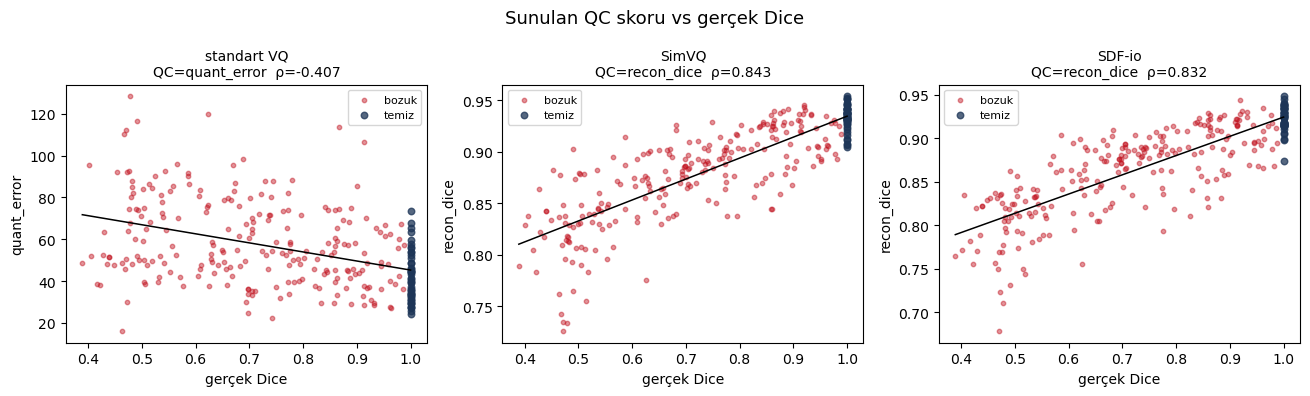

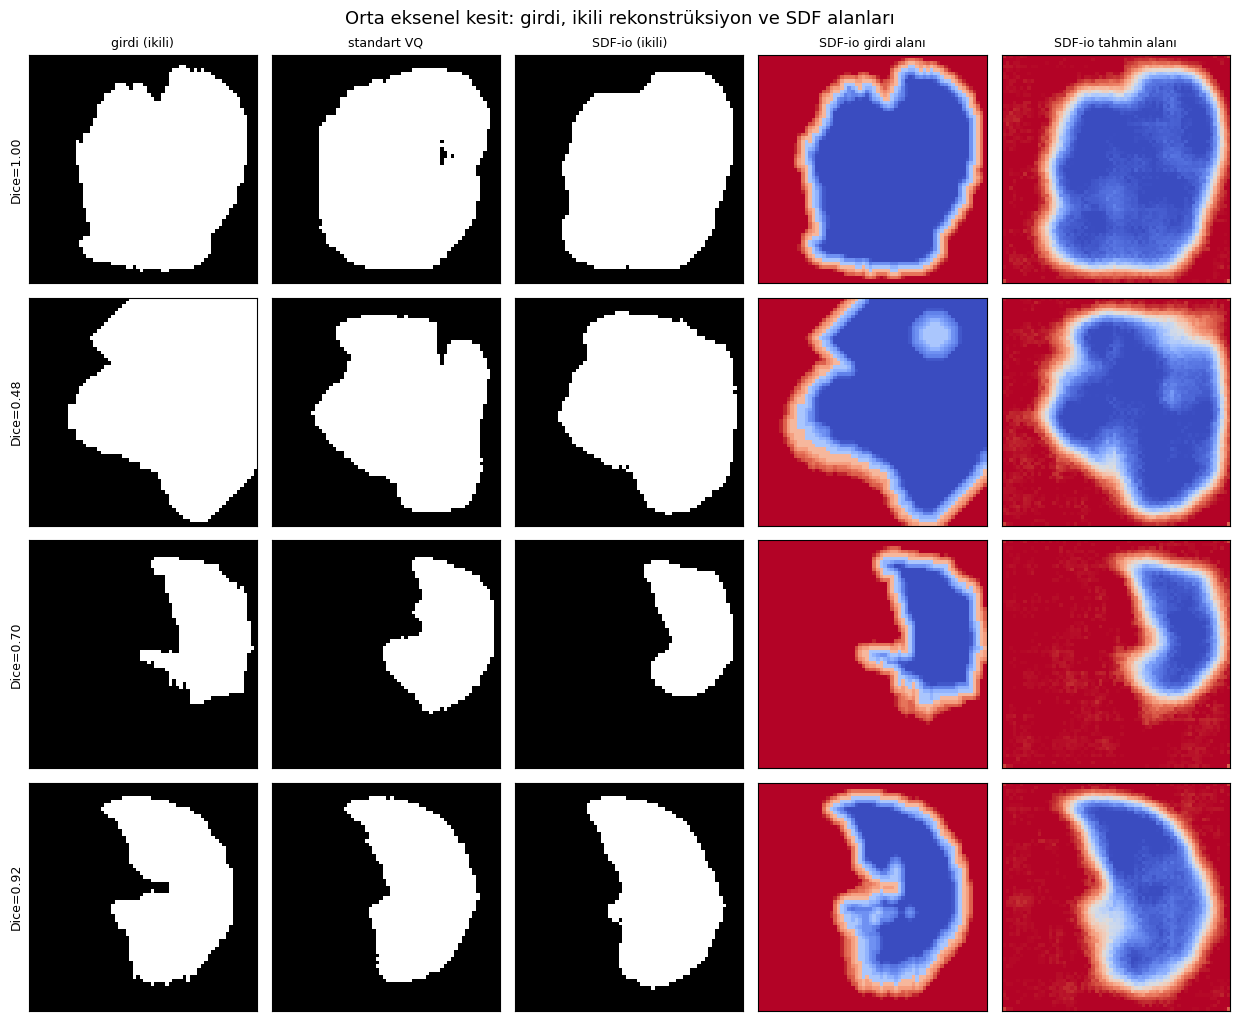

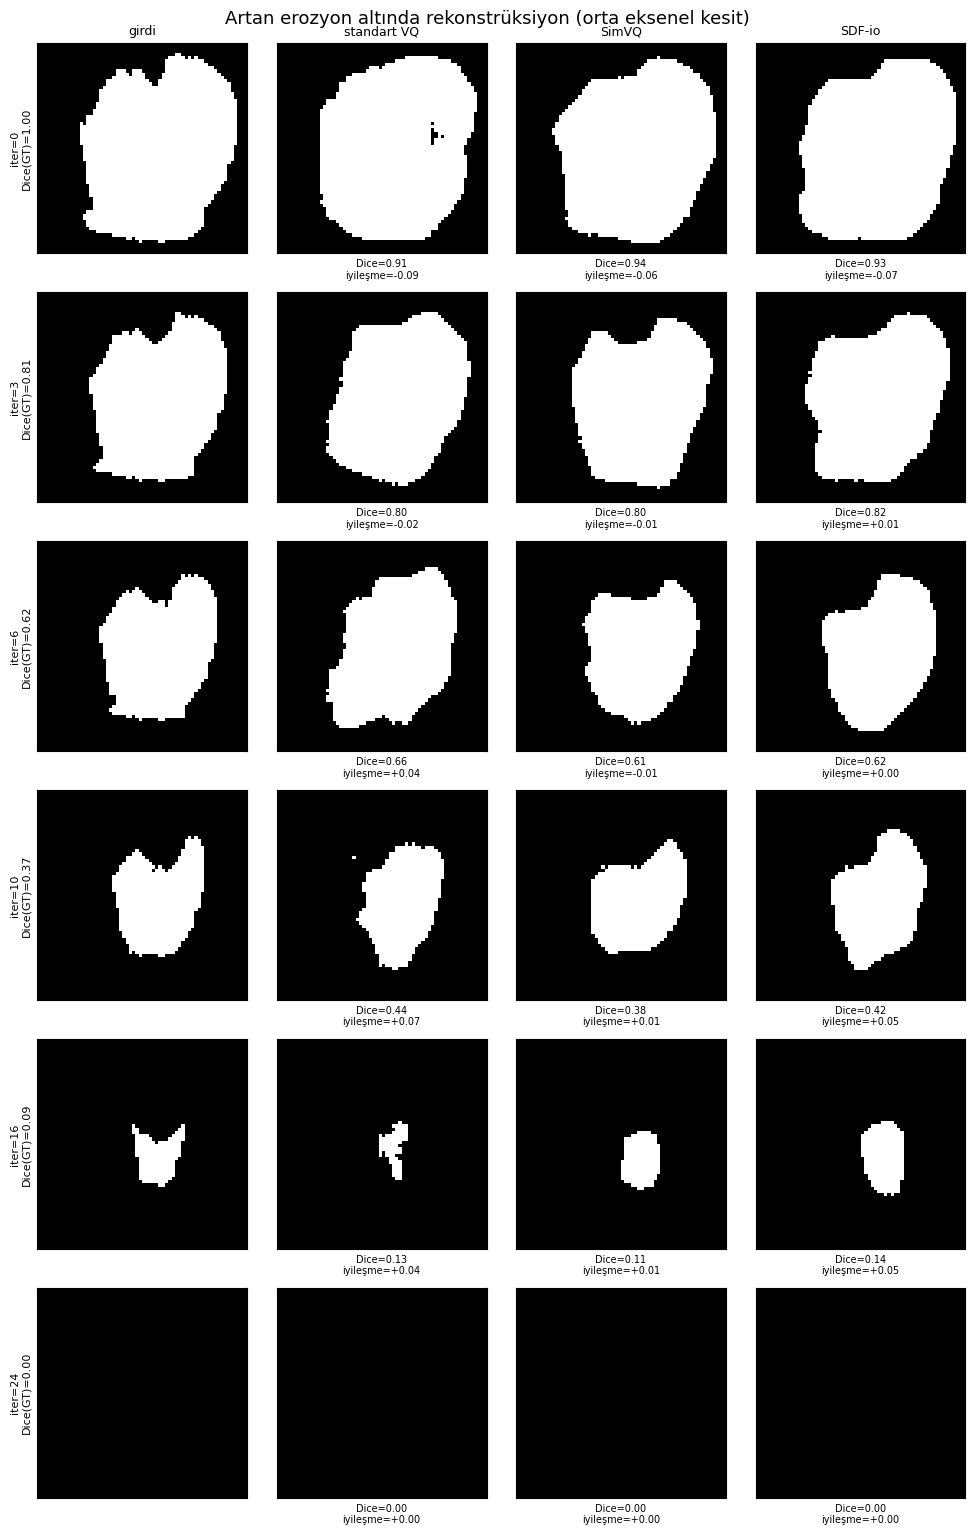

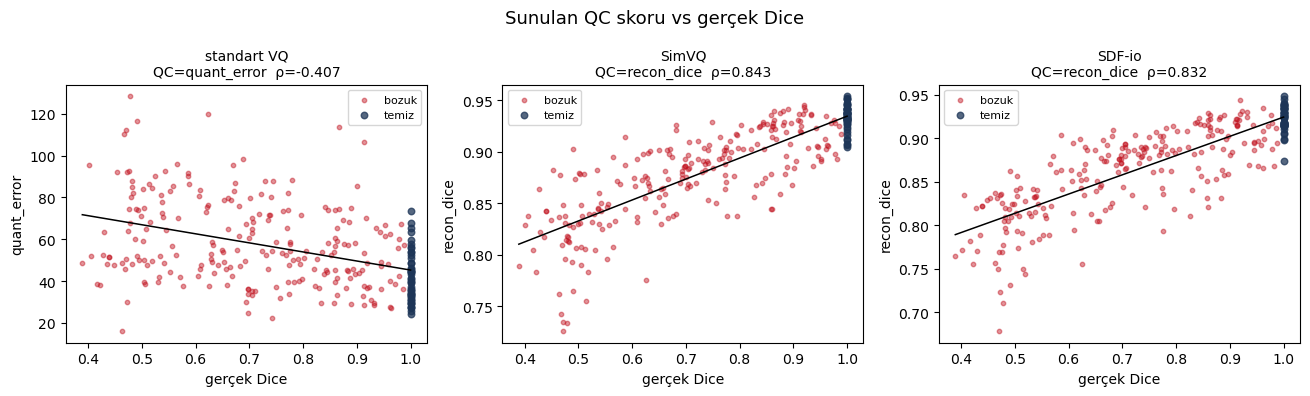

In [16]:
shown = [name for name, *_ in REGISTRY if name in results]
n = len(shown)
fig, axes = plt.subplots(1, n, figsize=(4.4 * n, 4.0))
if n == 1: axes = [axes]
for ax, name in zip(axes, shown):
    r = results[name]; s = r['scores'][r['qc']]
    rho = correlation(s, true_dice)['spearman']
    ax.scatter(true_dice[deg], s[deg], s=10, alpha=0.45, c='#c1121f', label='bozuk')
    ax.scatter(true_dice[is_clean], s[is_clean], s=22, alpha=0.75, c='#1d3557', label='temiz')
    order = np.argsort(true_dice); coef = np.polyfit(true_dice, s, 1)
    ax.plot(true_dice[order], np.polyval(coef, true_dice[order]), 'k-', lw=1.1)
    ax.set_title(f"{name}\nQC={r['qc']}  ρ={rho:.3f}", fontsize=10)
    ax.set_xlabel('gerçek Dice'); ax.set_ylabel(r['qc']); ax.legend(fontsize=8, loc='best')
fig.suptitle('Sunulan QC skoru vs gerçek Dice', fontsize=13)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'sdf_io_karsilastirma_scatter.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 8. Görsel rekonstrüksiyonlar — girdi vs SDF-io çıktısı

Orta eksenel kesitte: ikili girdi, standart VQ ve SDF-io ikili rekonstrüksiyonları. SDF-io için ayrıca
modelin gördüğü **girdi SDF alanı** ile ürettiği **tahmin SDF alanı** (ısı haritası) gösterilir.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\sdf_io_karsilastirma_gorseller.png


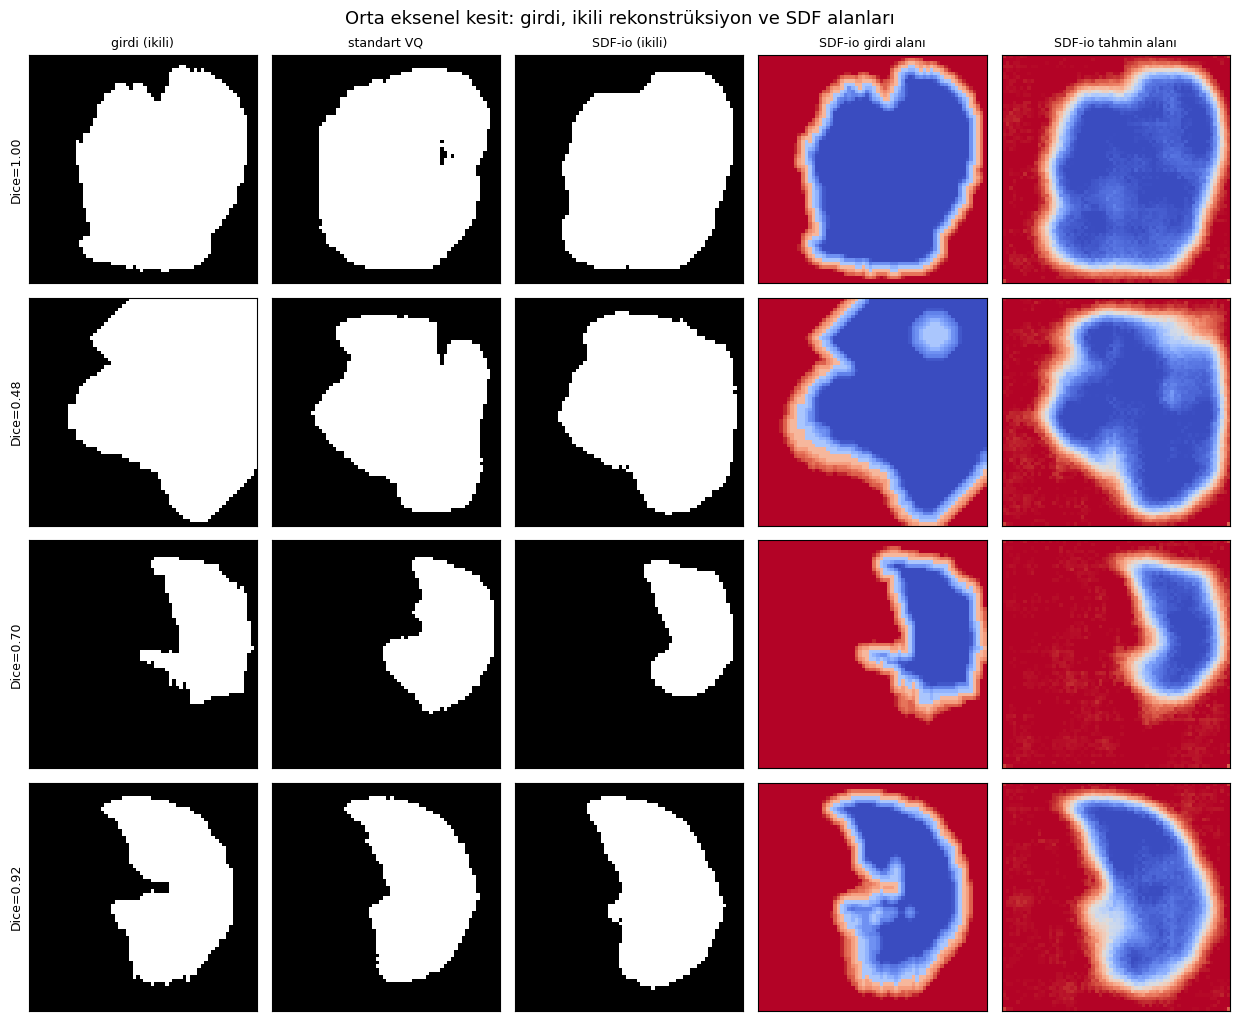

In [17]:
@torch.no_grad()
def bin_recon(model, mask):
    x = torch.from_numpy(mask.astype('float32'))[None, None].to(device)
    return (model.reconstruct(x)[0, 0].cpu().numpy() > 0.5)

@torch.no_grad()
def sdf_fields(model, mask):
    x = torch.from_numpy(mask.astype('float32'))[None, None].to(device)
    sdf_in = model.to_sdf_input(x)[0, 0].cpu().numpy()
    sdf_pred = model.predict_sdf(x)[0, 0].cpu().numpy()
    return sdf_in, sdf_pred

# 1 temiz + bozukların düşük/orta/yüksek Dice çeyrekleri
clean_idx = int(np.where(is_clean)[0][0])
deg_ids = np.where(deg)[0]
deg_sorted = deg_ids[np.argsort(true_dice[deg_ids])]
picks = [clean_idx] + [int(deg_sorted[int(q * (len(deg_sorted) - 1))]) for q in (0.1, 0.5, 0.9)]

vq_model = results['standart VQ']['model'] if 'standart VQ' in results else None
sdfio_model = results['SDF-io']['model']

cols = ['girdi (ikili)', 'standart VQ', 'SDF-io (ikili)', 'SDF-io girdi alanı', 'SDF-io tahmin alanı']
fig, axes = plt.subplots(len(picks), len(cols), figsize=(2.5 * len(cols), 2.6 * len(picks)))
axes = np.atleast_2d(axes)
for rr, mi in enumerate(picks):
    mask = masks[mi]; zc = mask.shape[0] // 2; td = true_dice[mi]
    sdf_in, sdf_pred = sdf_fields(sdfio_model, mask)
    panels = [
        (mask[zc], 'gray', None),
        (bin_recon(vq_model, mask)[zc] if vq_model is not None else np.zeros_like(mask[zc]), 'gray', None),
        (bin_recon(sdfio_model, mask)[zc], 'gray', None),
        (sdf_in[zc], 'coolwarm', (-1, 1)),
        (sdf_pred[zc], 'coolwarm', (-1, 1)),
    ]
    for c, (img, cmap, lim) in enumerate(panels):
        ax = axes[rr, c]
        if lim: ax.imshow(img, cmap=cmap, vmin=lim[0], vmax=lim[1])
        else:   ax.imshow(img, cmap=cmap)
        if rr == 0: ax.set_title(cols[c], fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    axes[rr, 0].set_ylabel(f'Dice={td:.2f}', fontsize=9)
fig.suptitle('Orta eksenel kesit: girdi, ikili rekonstrüksiyon ve SDF alanları', fontsize=13)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'sdf_io_karsilastirma_gorseller.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 10. Parametrik erozyon taraması — modeller aşırı bozulmaya nasıl tepki veriyor?

Yukarıdaki (bölüm 8) görsellerde girdi hem temiz hem bozuk örnekler karışıktı. Burada **tek bir temiz
maskeye giderek artan erozyon** uygularız; erozyon şiddeti `apply_erosion(mask, iters)` fonksiyonundaki
**iterasyon sayısı** ile parametrik olarak kontrol edilir. Her satır bir erozyon seviyesidir:
sol sütun girdinin GT'ye Dice'ını, model sütunları rekonstrüksiyonun GT'ye Dice'ını gösterir.
İyi bir kalite modeli girdi bozuldukça rekonstrüksiyonu öğrendiği şekle **geri çekmeli** (tamamlama);
`iyileşme = Dice(rekon, GT) − Dice(girdi, GT)` bunu ölçer.

erozyon taraması (iyileşme = Dice(rekon,GT) - Dice(girdi,GT)):
  iter= 0 | girdi Dice=1.00  |  standart VQ: rekon=0.91 (iyileşme -0.09)  |  SimVQ: rekon=0.94 (iyileşme -0.06)  |  SDF-io: rekon=0.93 (iyileşme -0.07)
  iter= 3 | girdi Dice=0.81  |  standart VQ: rekon=0.80 (iyileşme -0.02)  |  SimVQ: rekon=0.80 (iyileşme -0.01)  |  SDF-io: rekon=0.82 (iyileşme +0.01)
  iter= 6 | girdi Dice=0.62  |  standart VQ: rekon=0.66 (iyileşme +0.04)  |  SimVQ: rekon=0.61 (iyileşme -0.01)  |  SDF-io: rekon=0.62 (iyileşme +0.00)
  iter=10 | girdi Dice=0.37  |  standart VQ: rekon=0.44 (iyileşme +0.07)  |  SimVQ: rekon=0.38 (iyileşme +0.01)  |  SDF-io: rekon=0.42 (iyileşme +0.05)
  iter=16 | girdi Dice=0.09  |  standart VQ: rekon=0.13 (iyileşme +0.04)  |  SimVQ: rekon=0.11 (iyileşme +0.01)  |  SDF-io: rekon=0.14 (iyileşme +0.05)
  iter=24 | girdi Dice=0.00  |  standart VQ: rekon=0.00 (iyileşme +0.00)  |  SimVQ: rekon=0.00 (iyileşme +0.00)  |  SDF-io: rekon=0.00 (iyileşme +0.00)

kaydedildi: C:\Users\ahm

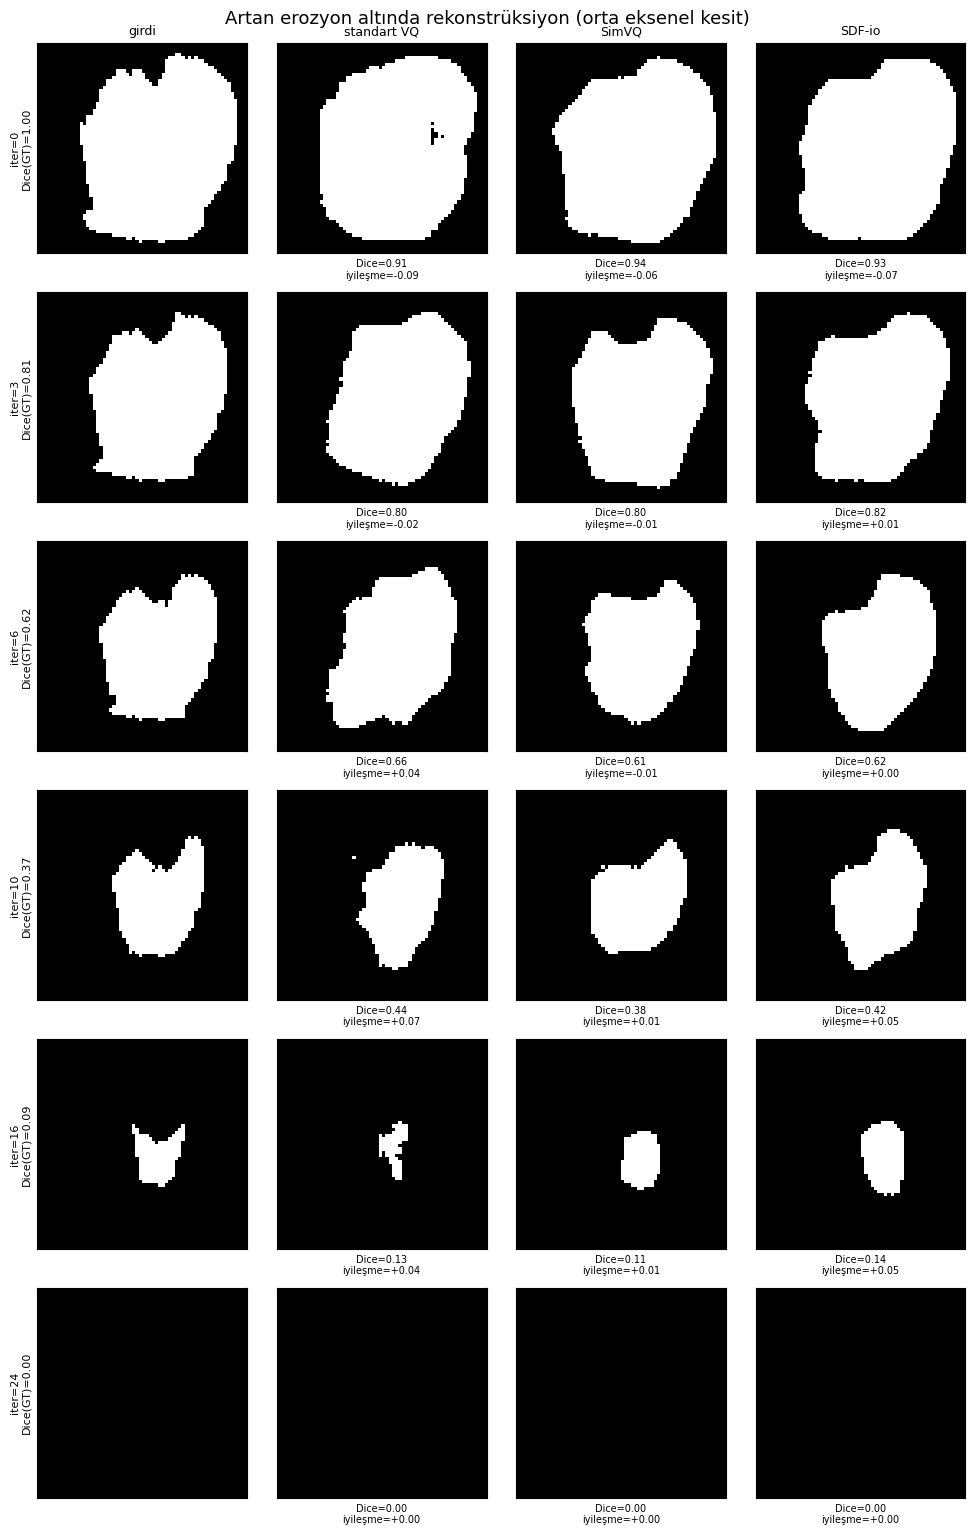

In [18]:
from scipy.ndimage import binary_erosion

def apply_erosion(mask, iters):
    """Parametrik erozyon: iterasyon sayısı = erozyon şiddeti (0 = temiz)."""
    if iters <= 0:
        return mask.astype('float32')
    out = binary_erosion(mask > 0.5, iterations=int(iters))
    return out.astype('float32')

def _dice(a, b):
    a = a > 0.5; b = b > 0.5
    return float(2 * (a & b).sum() / (a.sum() + b.sum() + 1e-8))

# tek bir TEMİZ maske seç (GT referansı)
gt = masks[clean_idx].astype('float32')

# parametrik erozyon seviyeleri (iterasyon sayısı) — istediğin gibi değiştir
EROSION_ITERS = [0, 3, 6, 10, 16, 24]

sweep_models = [(n, results[n]['model']) for n in ('standart VQ', 'SimVQ', 'SDF-io') if n in results]
cols = ['girdi'] + [n for n, _ in sweep_models]

print('erozyon taraması (iyileşme = Dice(rekon,GT) - Dice(girdi,GT)):')
fig, axes = plt.subplots(len(EROSION_ITERS), len(cols),
                         figsize=(2.5 * len(cols), 2.6 * len(EROSION_ITERS)))
axes = np.atleast_2d(axes)
for r, it in enumerate(EROSION_ITERS):
    inp = apply_erosion(gt, it)
    din = _dice(inp, gt)
    zc = inp.shape[0] // 2
    axes[r, 0].imshow(inp[zc], cmap='gray')
    axes[r, 0].set_ylabel(f'iter={it}\nDice(GT)={din:.2f}', fontsize=8)
    if r == 0:
        axes[r, 0].set_title('girdi', fontsize=9)
    line = f'  iter={it:2d} | girdi Dice={din:.2f}'
    for c, (name, model) in enumerate(sweep_models, start=1):
        rec = bin_recon(model, inp)
        drec = _dice(rec, gt)
        axes[r, c].imshow(rec[zc], cmap='gray')
        axes[r, c].set_xlabel(f'Dice={drec:.2f}\niyileşme={drec - din:+.2f}', fontsize=7)
        if r == 0:
            axes[r, c].set_title(name, fontsize=9)
        line += f'  |  {name}: rekon={drec:.2f} (iyileşme {drec - din:+.2f})'
    print(line)
    for c in range(len(cols)):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
fig.suptitle('Artan erozyon altında rekonstrüksiyon (orta eksenel kesit)', fontsize=13)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'sdf_io_erozyon_taramasi.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('\nkaydedildi:', out); plt.show()

## 9. Bulguların özeti

- **SDF-io bozuk maskeleri ayırt edebiliyor:** sunulan QC skoru `recon_dice` gerçek Dice ile güçlü
  korelasyon gösterir (genel Spearman ρ ≈ 0.83). Yani model, kötü maskeyi öğrendiği şekil manifolduna
  çekerek girdi-rekonstrüksiyon farkı üzerinden kaliteyi sıralayabiliyor.
- **Ama SDF girdisi ek fayda sağlamıyor:** `recon_dice` ρ standart VQ (ikili girdi) ile aynı seviyede
  (~0.83); codebook-mesafesi `quant_error` ise standart VQ'nun 0.86'sının belirgin altında (~0.45).
  SDF autoencoder rekonstrüksiyonu iyi (Dice ≈ 0.93) ama kalite kestirimine yeni bir katkı getirmiyor.
- **SDF-io da standart VQ gibi codebook çöküşüne uğrar** (değerlendirme kümesinde ~onlarca kod),
  SimVQ'nun aksine; bu sayede `quant_error` sinyali tamamen kaybolmaz ama zayıftır.
- **Sonuç:** girdiyi sürekli SDF alanına taşımak, ikili-girdi VQ-VAE'ye kıyasla GT'siz kalite kestirimini
  iyileştirmedi. Sunulacak skor yine `recon_dice`'tır.

Üretilen dosyalar: `outputs/sdf_io_karsilastirma_scatter.png`, `outputs/sdf_io_karsilastirma_gorseller.png`., `outputs/sdf_io_erozyon_taramasi.png`
